# 1. Exploração do corpus e do índice invertido

Neste notebook olhamos os dados que alimentam o buscador e verificamos duas leis
clássicas de RI sobre o vocabulário das letras: **Zipf** e **Heaps**.

> Antes, rode `python scripts/baixar_dados.py` e `python scripts/construir_indice.py`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # para importar o pacote `buscador`

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.figsize"] = (9, 4)

In [2]:
from buscador import MotorDeBusca
from buscador.texto import tokenizar

motor = MotorDeBusca.carregar(semantico=False)
corpus = motor.corpus
print(f"{len(corpus):,} músicas | {corpus['artista'].nunique():,} artistas")
corpus.head()

20,000 músicas | 540 artistas


,titulo,artista,letra,idioma,generos,popularidade,link_musica,link_artista
0,Menina Má,Anitta,"Me olha e deseja que eu veja\nMas já digo: ""não vai rolar!""\nAgora é tarde p...",pt,Pop; Dance; Funk Carioca,119.6,/anitta/menina-ma.html,/anitta/
1,Show Das Poderosas,Anitta,Prepara que agora é a hora\nDo show das poderosas\nQue descem e rebolam\nAfr...,pt,Pop; Dance; Funk Carioca,119.6,/anitta/show-das-poderosas.html,/anitta/
2,Meiga e Abusada,Anitta,"Eu, posso conquistar tudo que eu quero\nMas, foi tão fácil pra te controlar\...",pt,Pop; Dance; Funk Carioca,119.6,/anitta/meiga-e-abusada.html,/anitta/
3,Bang,Anitta,"Vem na maldade, com vontade\nChega encosta em mim\nHoje eu quero e você sabe...",pt,Pop; Dance; Funk Carioca,119.6,/anitta/bang.html,/anitta/
4,Zen,Anitta,"Uh Uh Uh Uh\n\nOlha 'cê' me faz tão bem\nSó de olhar teus olhos, baby eu fic...",pt,Pop; Dance; Funk Carioca,119.6,/anitta/zen.html,/anitta/


## 1.1 Composição do corpus

O corpus tem as músicas dos artistas mais populares do Vagalume, com no máximo 40
músicas por artista, para não ficar dominado por poucos nomes.

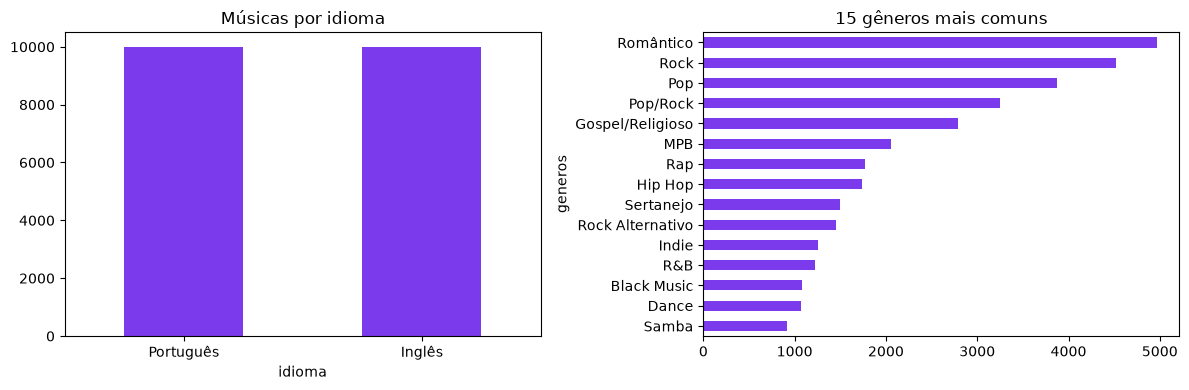

In [3]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
corpus["idioma"].map({"pt": "Português", "en": "Inglês"}).value_counts().plot.bar(ax=eixos[0], rot=0, color="#7c3aed")
eixos[0].set_title("Músicas por idioma")
generos = corpus["generos"].str.split(";").explode().str.strip()
generos[generos != ""].value_counts().head(15).sort_values().plot.barh(ax=eixos[1], color="#7c3aed")
eixos[1].set_title("15 gêneros mais comuns")
plt.tight_layout()

,count,mean,std,min,25%,50%,75%,max
idioma,,,,,,,,
en,10000.0,289.0,168.0,14.0,179.0,254.0,353.0,3302.0
pt,10000.0,184.0,140.0,15.0,104.0,147.0,220.0,2490.0


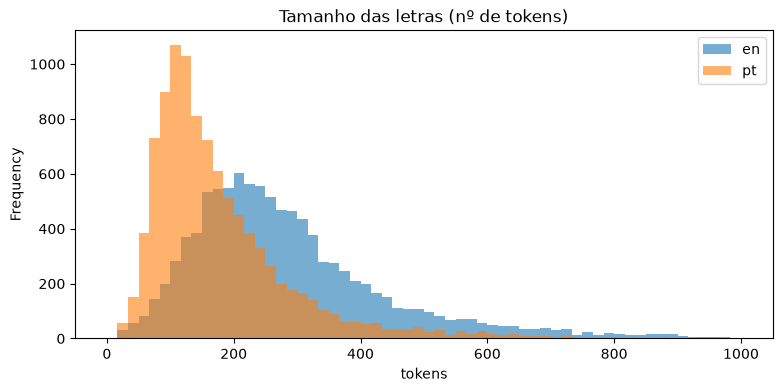

In [4]:
comprimentos = pd.Series(motor.indices["letra"].comprimentos, name="tokens")
ax = comprimentos.groupby(corpus["idioma"]).plot.hist(bins=60, range=(0, 1000), alpha=.6, legend=True)
plt.title("Tamanho das letras (nº de tokens)"); plt.xlabel("tokens")
comprimentos.groupby(corpus["idioma"]).describe().round(0)

## 1.2 O índice invertido

Um índice para cada campo (letra, título e artista). Cada termo aponta para a lista
ordenada das músicas em que aparece (postings) e o tf em cada uma.

In [5]:
for campo, indice in motor.indices.items():
    tamanho_mb = (indice.docs.nbytes + indice.freqs.nbytes + indice.inicio.nbytes) / 1e6
    print(f"{campo:8s} {len(indice):>7,} termos  {len(indice.docs):>9,} postings  ~{tamanho_mb:.1f} MB")

letra     75,198 termos  1,917,271 postings  ~15.9 MB
titulo    11,456 termos     63,687 postings  ~0.6 MB
artista      895 termos     40,511 postings  ~0.3 MB
documento  76,150 termos  1,961,883 postings  ~16.3 MB


In [6]:
indice = motor.indices["letra"]
docs, tf = indice.postings("saudade")
print(f"'saudade' aparece em {indice.frequencia_documento('saudade')} letras")
pd.DataFrame({"doc_id": docs[:8], "tf": tf[:8],
              "música": [motor.textos["titulo"][d] + " — " + motor.textos["artista"][d] for d in docs[:8]]})

'saudade' aparece em 786 letras


,doc_id,tf,música
0,6,3,Some Que Ele Vem Atrás (Part. Marília Mendonça) — Anitta
1,15,3,Mulher — Anitta
2,31,4,Cobertor (Part. Projota) — Anitta
3,77,3,Duas Doses de Saudade — Ludmilla
4,82,2,212 — Ludmilla
5,93,2,Ela Não — Ludmilla
6,96,1,Amor Difícil (part. Thiaguinho) — Ludmilla
7,98,2,Vai e Volta — Ludmilla


In [7]:
# termos com maior frequência de documento (df): são as "stopwords" naturais
ordem = np.argsort(-indice.df)[:20]
pd.DataFrame({"termo": [indice.termos[i] for i in ordem], "df": indice.df[ordem],
              "% das letras": (100 * indice.df[ordem] / indice.n_docs).round(1)}).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
termo,a,me,to,so,do,no,e,the,o,and,i,que,you,de,in,nao,my,eu,it,of
df,17216,13696,10461,9857,9790,9735,9654,9569,9284,9118,9067,9008,8992,8694,8026,7461,7459,7407,7217,6949
% das letras,86.1,68.5,52.3,49.3,49.0,48.7,48.3,47.8,46.4,45.6,45.3,45.0,45.0,43.5,40.1,37.3,37.3,37.0,36.1,34.7


## 1.3 Lei de Zipf

A frequência do *r*-ésimo termo mais comum é aproximadamente proporcional a 1/*r*.
Em escala log-log isso vira uma reta com inclinação perto de −1.

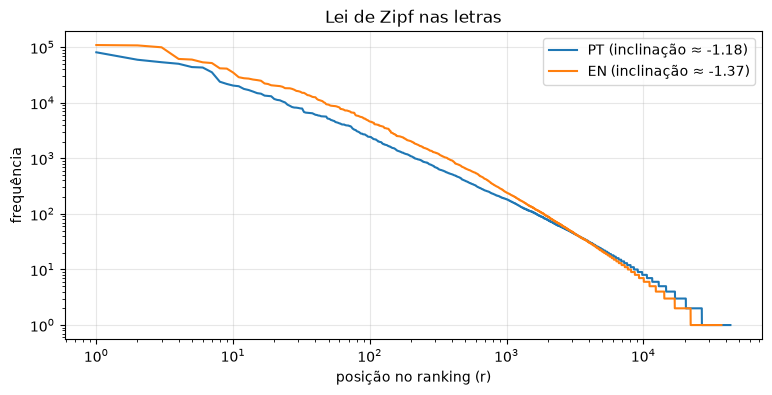

In [8]:
from collections import Counter

frequencias = {}
for idioma in ["pt", "en"]:
    contagem = Counter()
    for letra in corpus.loc[corpus["idioma"] == idioma, "letra"]:
        contagem.update(tokenizar(letra))
    frequencias[idioma] = np.array(sorted(contagem.values(), reverse=True))

for idioma, f in frequencias.items():
    r = np.arange(1, len(f) + 1)
    inclinacao, _ = np.polyfit(np.log(r[:5000]), np.log(f[:5000]), 1)
    plt.loglog(r, f, label=f"{idioma.upper()} (inclinação ≈ {inclinacao:.2f})")
plt.xlabel("posição no ranking (r)"); plt.ylabel("frequência"); plt.title("Lei de Zipf nas letras")
plt.legend(); plt.grid(alpha=.3)

## 1.4 Lei de Heaps

O vocabulário cresce como *V = K·n^β* (com β entre 0,4 e 0,6 em textos comuns):
sempre aparecem palavras novas, mas cada vez mais devagar.

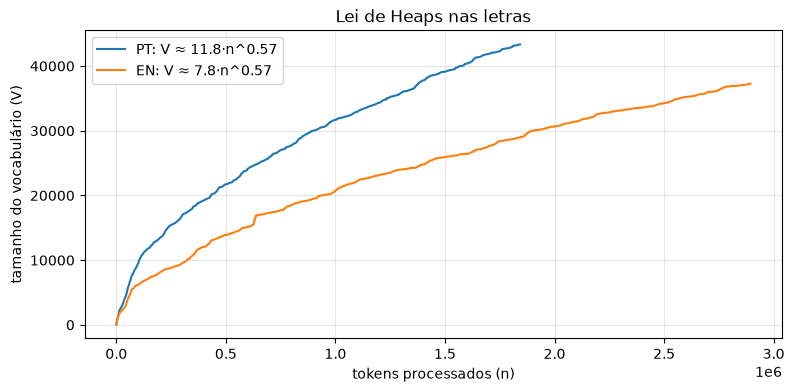

In [9]:
for idioma in ["pt", "en"]:
    vistos, n, xs, ys = set(), 0, [], []
    for letra in corpus.loc[corpus["idioma"] == idioma, "letra"]:
        tokens = tokenizar(letra)
        vistos.update(tokens); n += len(tokens)
        xs.append(n); ys.append(len(vistos))
    beta, logk = np.polyfit(np.log(xs[10:]), np.log(ys[10:]), 1)
    plt.plot(xs, ys, label=f"{idioma.upper()}: V ≈ {np.exp(logk):.1f}·n^{beta:.2f}")
plt.xlabel("tokens processados (n)"); plt.ylabel("tamanho do vocabulário (V)")
plt.title("Lei de Heaps nas letras"); plt.legend(); plt.grid(alpha=.3)

## 1.5 Os modelos na prática

A mesma consulta em modelos diferentes. O booleano devolve um conjunto sem ordem de
relevância (aqui, ordenado por popularidade). O TF-IDF com cosseno tende a favorecer
letras curtas, e o BM25 controla isso melhor com a saturação do tf (k1) e a
normalização por tamanho (b).

In [10]:
def comparar(consulta, modos=("booleano", "tfidf", "bm25"), k=5):
    colunas = {}
    for modo in modos:
        ranking, _ = motor.ranquear(consulta, modo, k=k)
        colunas[modo] = [f"{motor.textos['titulo'][d]} — {motor.textos['artista'][d]}" for d, _ in ranking]
        colunas[modo] += [""] * (k - len(colunas[modo]))
    return pd.DataFrame(colunas, index=range(1, k + 1))

comparar("mother mary comes to me")

,booleano,tfidf,bm25
1,Let It Be — The Beatles,Mary Jane — Janis Joplin,Let It Be — Paul McCartney
2,The Beast — Fugees,Hello Mary Lou — Creedence Clearwater Revival,Let It Be — The Beatles
3,Let It Be — Paul McCartney,Let It Be — The Beatles,Buddha For Mary — Thirty Seconds To Mars
4,,Let It Be — Paul McCartney,Ave Mary A — Pink
5,,Buddha For Mary — Thirty Seconds To Mars,Lady Writer — Dire Straits


In [11]:
comparar("legião urbana tempo")

,booleano,tfidf,bm25
1,Tempo Perdido — Legião Urbana,A Tempestade — Legião Urbana,Tempo Perdido — Legião Urbana
2,Faroeste Caboclo — Legião Urbana,Eu Sei — Legião Urbana,1977 — Legião Urbana
3,Índios — Legião Urbana,Antes Das Seis — Legião Urbana,Vento No Litoral — Legião Urbana
4,Vento No Litoral — Legião Urbana,Tempo Perdido — Legião Urbana,Química — Legião Urbana
5,Química — Legião Urbana,Hoje a Noite Não Tem Luar — Legião Urbana,Daniel na Cova dos Leões — Legião Urbana


### Tolerância a erros

O corretor usa o índice de bigramas para achar candidatos, a distância de edição
para filtrar e o **contexto** (as outras palavras da consulta) para escolher.

In [12]:
for consulta in ["coracao partdo", "partdo", "imagin all the peple", "eu sei que vou te amra", "hotel califronia"]:
    print(f"{consulta!r:28} -> {motor.corretor.corrigir_consulta(consulta)[0]!r}")

'coracao partdo'             -> 'coracao partido'
'partdo'                     -> 'parado'
'imagin all the peple'       -> 'imagine all the people'
'eu sei que vou te amra'     -> 'eu sei que vou te amar'
'hotel califronia'           -> 'hotel california'


In [13]:
print(motor.booleano._expansor("letra").expandir("apaixon*")[:15])

['apaixonado', 'apaixonar', 'apaixonei', 'apaixonada', 'apaixonou', 'apaixona', 'apaixonados', 'apaixono', 'apaixonasse', 'apaixonadamente', 'apaixonando', 'apaixonadinha', 'apaixone', 'apaixonadim', 'apaixonadinho']
